# Entregable 3 · Datos reales y validación por estudiante

Este notebook nuevo conserva intactos los notebooks de la primera entrega. No forma parte de los Books anteriores.

La preparación y el entrenamiento reproducible viven en `entregable3.py`. Ejecutar `venv\Scripts\python.exe entregable3.py` desde Precalculo antes de actualizar estas tablas. El dashboard lee los mismos artefactos de `resultados/e3/`.

Se reserva 202530 como test y se purgan de train los estudiantes del periodo test. GroupKFold anidado usa cinco folds externos y cinco internos por estudiante. El grid se elige por RMSE en train. ID, periodo y nota_final quedan fuera de las predictoras. Los outliers reales se conservan.

In [1]:
from pathlib import Path
import json
import pandas as pd
from entregable3 import load_partitions, source_hashes, OUTPUT
train, test, audit = load_partitions()
report = json.loads((OUTPUT / 'modelos_lineales.json').read_text(encoding='utf-8'))
assert source_hashes() == report['source_sha256'], 'Reejecutar entregable3.py'
display(pd.DataFrame([audit]).T.rename(columns={0: 'Valor'}))

,Valor
source_rows,1527
source_students,1506
missing_target,30
test_period,202530
train_periods,"[202310, 202330, 202410, 202430, 202510]"
purged_overlap_rows,0
purged_overlap_students,0
train_raw,1309
test_raw,188
excluded_train,0


## EDA · solo datos reales de entrenamiento

,count,mean,std,min,25%,50%,75%,max
Icfes_nuevo,1309.0,341.157372,47.900234,0.000000,314.000000,345.000000,370.000000,477.000000
Icfes_Matematicas,1309.0,68.473644,10.209590,0.000000,64.000000,69.000000,74.000000,100.000000
Tiempo_empleado_en_la_verificación_de_conocimientos,1288.0,0.736931,0.614113,0.016667,0.316667,0.533333,0.950000,4.600000
Dominio_Inicial,1309.0,9.038197,16.168505,0.000000,0.000000,2.000000,10.000000,140.000000
avance_precalculo_aleks,1309.0,27.513369,20.387061,0.000000,10.000000,26.000000,38.000000,121.000000
Dominio_Final,1309.0,36.551566,27.168769,0.000000,16.000000,32.000000,49.000000,143.000000
Tiempo_Total_Tiempo,1304.0,18.045284,12.615387,0.000000,8.162500,16.033333,25.495833,122.450000
Tiempo_total_Aprendidos_hora,1304.0,1.554245,0.914249,0.000000,0.990938,1.439966,1.993349,6.937601
nota_primer_parcial,1309.0,3.499358,1.118030,0.500000,2.600000,3.700000,4.500000,5.000000


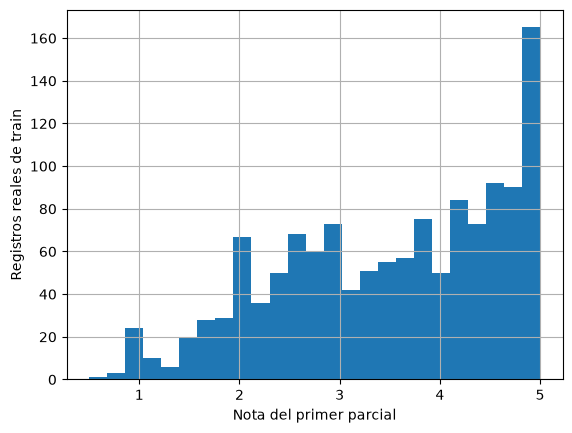

,Icfes_nuevo,Icfes_Matematicas,Tiempo_empleado_en_la_verificación_de_conocimientos,Dominio_Inicial,avance_precalculo_aleks,Dominio_Final,Tiempo_Total_Tiempo,Tiempo_total_Aprendidos_hora,nota_primer_parcial
Icfes_nuevo,1.000000,0.834998,0.360028,0.528350,0.259404,0.437964,-0.008059,0.441180,0.536757
Icfes_Matematicas,0.834998,1.000000,0.269767,0.384462,0.176875,0.308980,-0.009322,0.316762,0.428011
Tiempo_empleado_en_la_verificación_de_conocimientos,0.360028,0.269767,1.000000,0.761287,0.104767,0.425860,-0.033973,0.153813,0.364530
Dominio_Inicial,0.528350,0.384462,0.761287,1.000000,0.195257,0.580462,-0.082681,0.403302,0.496895
avance_precalculo_aleks,0.259404,0.176875,0.104767,0.195257,1.000000,0.843469,0.794865,0.565978,0.287777
Dominio_Final,0.437964,0.308980,0.425860,0.580462,0.843469,1.000000,0.582632,0.565250,0.455872
Tiempo_Total_Tiempo,-0.008059,-0.009322,-0.033973,-0.082681,0.794865,0.582632,1.000000,0.070393,0.052893
Tiempo_total_Aprendidos_hora,0.441180,0.316762,0.153813,0.403302,0.565978,0.565250,0.070393,1.000000,0.382104
nota_primer_parcial,0.536757,0.428011,0.364530,0.496895,0.287777,0.455872,0.052893,0.382104,1.000000


In [2]:
from entregable3 import NUMERIC, TARGET
import matplotlib.pyplot as plt
display(train[NUMERIC + [TARGET]].describe().T)
train[TARGET].hist(bins=25)
plt.xlabel('Nota del primer parcial')
plt.ylabel('Registros reales de train')
plt.show()
display(train[NUMERIC + [TARGET]].corr(method='spearman'))

## Grid y evaluación anidada
La búsqueda final selecciona parámetros; las predicciones OOF se calculan con búsquedas independientes dentro de cada fold externo. El test temporal solo se evalúa después del ajuste.

In [3]:
grid = pd.read_csv(OUTPUT / 'grid_search.csv')
grid['RMSE medio'] = -grid['mean_test_score']
display(grid.sort_values('rank_test_score'))
display(pd.DataFrame(report['fold_audit']))
display(pd.DataFrame(report['cv']))
display(pd.DataFrame(report['test']))

,param_modelo__C,param_modelo__epsilon,mean_test_score,std_test_score,rank_test_score,RMSE medio
29,0.30,0.50,-0.821690,0.045407,1,0.821690
21,0.10,0.50,-0.822370,0.046659,2,0.822370
37,1.00,0.50,-0.824597,0.046941,3,0.824597
20,0.10,0.30,-0.826001,0.046241,4,0.826001
45,10.00,0.50,-0.826382,0.045048,5,0.826382
28,0.30,0.30,-0.827840,0.047108,6,0.827840
16,0.10,0.00,-0.828117,0.047138,7,0.828117
30,0.30,0.75,-0.828308,0.043898,8,0.828308
17,0.10,0.05,-0.828598,0.047684,9,0.828598
18,0.10,0.10,-0.828895,0.044985,10,0.828895


,fold,fit_rows,validation_rows,fit_students,validation_students,shared_students,best_params
0,1,1047,262,1035,258,0,"{'modelo__C': 0.1, 'modelo__epsilon': 0.2}"
1,2,1047,262,1034,259,0,"{'modelo__C': 0.3, 'modelo__epsilon': 0.5}"
2,3,1047,262,1034,259,0,"{'modelo__C': 0.1, 'modelo__epsilon': 0.3}"
3,4,1047,262,1034,259,0,"{'modelo__C': 0.1, 'modelo__epsilon': 0.2}"
4,5,1048,261,1035,258,0,"{'modelo__C': 0.1, 'modelo__epsilon': 0.2}"


,modelo,metrica,media_cv,sd_cv
0,SVM lineal,RMSE,0.826140,0.041328
1,SVM lineal,MAE,0.649312,0.035291
2,SVM lineal,MAPE,24.083710,1.821257
3,SVM lineal,R2,0.450132,0.058012
4,Dummy media,RMSE,1.118000,0.026711
5,Dummy media,MAE,0.962418,0.025591
6,Dummy media,MAPE,37.298790,1.814612
7,Dummy media,R2,-0.003463,0.004465


,modelo,RMSE,MAE,MAPE_%,R2
0,SVM lineal,0.927706,0.755443,29.664556,0.428543
1,Dummy media,1.256059,1.104467,42.314507,-0.047571


## Incertidumbre y límites
Los intervalos remuestrean estudiantes del test (1.000 veces), conservando juntos sus registros. No se recortan predicciones. GroupKFold evalúa estudiantes nuevos, pero no orden temporal; el test 202530 mide este último. Categorías no vistas se codifican según el pipeline. Los coeficientes no son causales y LinearSVR no calcula p-valores.

In [4]:
display(pd.DataFrame(report['bootstrap']))
display(pd.DataFrame(report['residuals']))
display(pd.DataFrame(report['learning']))

,modelo,metrica,estimación,IC_2.5%,IC_97.5%
0,SVM lineal,RMSE,0.927706,0.838232,1.018473
1,SVM lineal,MAPE_%,29.664556,23.978393,36.508485
2,SVM lineal,R2,0.428543,0.320514,0.509091
3,Dummy media,RMSE,1.256059,1.174016,1.344446
4,Dummy media,MAPE_%,42.314507,34.809014,50.549681
5,Dummy media,R2,-0.047571,-0.151286,-0.004056


,modelo,media_residuo,normaltest_p,Breusch_Pagan_p,Spearman_abs_resid_vs_ajustado
0,SVM lineal,0.098933,0.007499,0.000257,-0.351859
1,Dummy media,0.267663,0.000034,NaN,NaN


,n_entrenamiento,RMSE_train_media,RMSE_validacion_media
0,261,0.793676,0.878238
1,523,0.778768,0.859596
2,784,0.793459,0.829324
3,1047,0.798711,0.826140
